In [2]:
# ──  Dependencies ──────────────────────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
for pkg in ['rdkit','xgboost','imbalanced-learn','scikit-learn',
            'matplotlib','seaborn','openpyxl','torch','torch-geometric']:
    try: __import__(pkg.replace('-','_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')

Dependencies OK.


In [3]:
# ── Imports ────────────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


In [5]:
# ──  Load ────────────────────────────────────────────────────────────────
df_raw = pd.read_csv('/Users/yaminichitikela/Desktop/qsar casepase/qsar_cho-k1/AID_1346980_cleaned.csv',
    usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
             'PUBCHEM_ACTIVITY_SCORE','PUBCHEM_ACTIVITY_OUTCOME'])
print(f'Raw rows : {len(df_raw):,}')
print(df_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())
print(df_raw['PUBCHEM_ACTIVITY_SCORE'].describe())

Raw rows : 7,671
PUBCHEM_ACTIVITY_OUTCOME
Inactive        7320
Inconclusive     236
Active           115
Name: count, dtype: int64
count    7671.000000
mean        1.192674
std         7.448959
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        90.000000
Name: PUBCHEM_ACTIVITY_SCORE, dtype: float64


In [6]:
# ──   SMILES + deduplication ──────────────────────────────
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

df_raw['csmi'] = df_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df = df_raw.dropna(subset=['csmi'])
print(f'After parse : {len(df):,}  (removed {len(df_raw)-len(df)} invalid SMILES)')
df = df.drop_duplicates('csmi', keep='first').reset_index(drop=True)
print(f'After dedup : {len(df):,}')

[08:02:18] WARNING: not removing hydrogen atom without neighbors


After parse : 7,671  (removed 0 invalid SMILES)
After dedup : 7,671


Removed 236 inconclusive
Active   (1): 115
Inactive (0): 7,320
Ratio       : 63.7:1


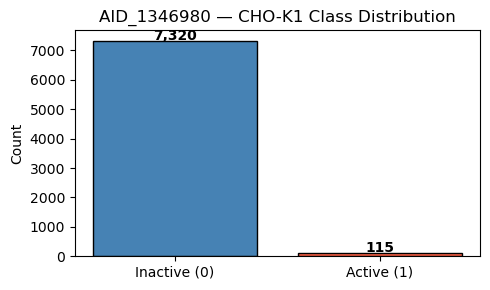

In [7]:
# ── Binary Labels
#  Active (score >= 40) -> 1 | Inactive (score = 0) -> 0 | Inconclusive -> drop
df['label'] = df['PUBCHEM_ACTIVITY_SCORE'].apply(
    lambda s: 1 if s>=40 else (0 if s==0 else np.nan))
n_inc = df['label'].isna().sum()
df = df.dropna(subset=['label']).copy()
df['label'] = df['label'].astype(int)

n_act, n_ina = (df['label']==1).sum(), (df['label']==0).sum()
print(f'Removed {n_inc:,} inconclusive')
print(f'Active   (1): {n_act:,}')
print(f'Inactive (0): {n_ina:,}')
print(f'Ratio       : {n_ina/n_act:.1f}:1')

fig, ax = plt.subplots(figsize=(5,3))
bars = ax.bar(['Inactive (0)','Active (1)'],[n_ina,n_act],
              color=['steelblue','tomato'], edgecolor='black')
for b,v in zip(bars,[n_ina,n_act]):
    ax.text(b.get_x()+b.get_width()/2, v+30, f'{v:,}', ha='center', fontweight='bold')
ax.set_title('AID_1346980 — CHO-K1 Class Distribution')
ax.set_ylabel('Count')
plt.tight_layout(); plt.savefig('cho_class_dist.png',dpi=150); plt.show()

In [8]:
# ── 5. Morgan ECFP4 (2048 bits) ─────────────────────────────────────────────
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps = df['csmi'].apply(smiles_to_ecfp4)
valid = fps.notna()
df    = df[valid].reset_index(drop=True)
fps   = fps[valid]
X_fp  = np.vstack(fps.values)   # (N, 2048)
y_all = df['label'].values
print(f'Fingerprint matrix : {X_fp.shape}')
print(f'FP density         : {X_fp.mean():.4f}')

[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerator
[08:02:18] DEPRECATION WARNING: please use MorganGenerat

Fingerprint matrix : (7435, 2048)
FP density         : 0.0135


In [9]:
# ──  Rich Atom Features (27-dim) & Bond Features (6-dim) — for GNN ─────────
ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0]*len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass
    return vec

from rdkit.Chem import rdchem
HYBRID_MAP = {
    rdchem.HybridizationType.SP  : 0,
    rdchem.HybridizationType.SP2 : 1,
    rdchem.HybridizationType.SP3 : 2,
}

def atom_feat(atom):
    at_oh  = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]  # 10-dim (+other)
    hyb    = [0,0,0,0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1
    deg    = min(atom.GetDegree(), 5)
    deg_oh = [0]*6; deg_oh[deg]=1
    fc     = atom.GetFormalCharge()
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0]
    extras = [
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        min(atom.GetTotalNumHs(), 4) / 4.0,
        atom.GetMass() / 100.0
    ]
    return at_oh + deg_oh + fc_enc + hyb + extras  # 10+6+3+4+4 = 27-dim

BOND_TYPES = [
    rdchem.BondType.SINGLE,
    rdchem.BondType.DOUBLE,
    rdchem.BondType.TRIPLE,
    rdchem.BondType.AROMATIC
]

def bond_feat(bond):
    bt = one_hot(bond.GetBondType(), BOND_TYPES)  # 4-dim
    return bt + [int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

from rdkit.Chem import MolFromSmiles
_mol = MolFromSmiles('CC(=O)O')
ATOM_DIM = len(atom_feat(_mol.GetAtomWithIdx(0)))
BOND_DIM  = len(bond_feat(_mol.GetBondWithIdx(0)))
print(f'Atom feature dim : {ATOM_DIM}')
print(f'Bond feature dim : {BOND_DIM}')

Atom feature dim : 27
Bond feature dim : 6


In [10]:
# ── 7. Build Graph Dataset ───────────────────────────────────────────────────
def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]
        ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    y = torch.tensor([label], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

graph_list = []
for smi, lbl in zip(df['csmi'].values, y_all):
    g = mol_to_graph(smi, lbl)
    if g: graph_list.append(g)

print(f'Graphs built: {len(graph_list):,}')
print(f'Example: {graph_list[0]}')

Graphs built: 7,435
Example: Data(x=[5, 27], edge_index=[2, 8], edge_attr=[8, 6], y=[1])


In [11]:
# ── 8. 20% External Test Split ───────────────────────────────────────────────
X_pool, X_test, y_pool, y_test = train_test_split(
    X_fp, y_all, test_size=0.20, stratify=y_all, random_state=SEED)

idx_all   = np.arange(len(y_all))
idx_pool, idx_test = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)

graphs_pool = [graph_list[i] for i in idx_pool]
graphs_test = [graph_list[i] for i in idx_test]

print(f'Pool : {len(y_pool):,}  (act={( y_pool==1).sum()}, ina={(y_pool==0).sum()})')
print(f'Test : {len(y_test):,}  (act={(y_test==1).sum()}, ina={(y_test==0).sum()})')

Pool : 5,948  (act=92, ina=5856)
Test : 1,487  (act=23, ina=1464)


In [12]:
# ── Print Test Set Values ─────────────────────────────────────────────────────
df_test = df.iloc[idx_test].reset_index(drop=True).copy()
df_test['label'] = y_test

print(f'Test set size : {len(df_test):,} compounds')
print(f'X_test shape  : {X_test.shape}   (compounds × ECFP4 bits)')
print(f'y_test shape  : {y_test.shape}')
print(f'\nClass distribution:')
print(f'  Active   (1): {(y_test == 1).sum():,}')
print(f'  Inactive (0): {(y_test == 0).sum():,}')

print(f'\n── First 20 test set compounds ──')
display(df_test[['PUBCHEM_CID', 'csmi', 'PUBCHEM_ACTIVITY_SCORE', 'label']].head(20))

print(f'\n── Fingerprint values (X_test) — first 5 rows, first 20 bits ──')
print(X_test[:5, :20])

print(f'\n── Labels (y_test) — first 20 values ──')
print(y_test[:20])

Test set size : 1,487 compounds
X_test shape  : (1487, 2048)   (compounds × ECFP4 bits)
y_test shape  : (1487,)

Class distribution:
  Active   (1): 23
  Inactive (0): 1,464

── First 20 test set compounds ──


,PUBCHEM_CID,csmi,PUBCHEM_ACTIVITY_SCORE,label
0,6387,CC(C)(C)S,0,0
1,3092,Cc1c(C(N)=O)cc([N+](=O)[O-])cc1[N+](=O)[O-],0,0
2,68191,CC(C)(CCl)c1ccccc1,0,0
3,62467,CCO[Si](C)(CCCOCC1CO1)OCC,0,0
4,5753,C[C@]12C[C@H](O)[C@H]3[C@@H](CCC4=CC(=O)CC[C@@...,0,0
5,4837,C1CNCCN1,0,0
6,5284369,Nc1ccccc1C(=O)OC/C=C/c1ccccc1,0,0
7,17168,COP(=S)(OC)Oc1ccc([N+](=O)[O-])cc1Cl,0,0
8,6377,CC1CN1,0,0
9,657220,CCC(=O)Oc1ccc(/C(CC)=C(\CC)c2ccc(OC(=O)CC)cc2)cc1,0,0



── Fingerprint values (X_test) — first 5 rows, first 20 bits ──
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

── Labels (y_test) — first 20 values ──
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [13]:
# ── 80/20 Train/Val Split from Pool ────────────────────────────────────────
X_tr_raw, X_val, y_tr_raw, y_val = train_test_split(
    X_pool, y_pool, test_size=0.20, stratify=y_pool, random_state=SEED)

pool_sub_idx = np.arange(len(y_pool))
tr_sub_idx, val_sub_idx = train_test_split(
    pool_sub_idx, test_size=0.20, stratify=y_pool, random_state=SEED)

graphs_val   = [graphs_pool[i] for i in val_sub_idx]
graphs_trraw = [graphs_pool[i] for i in tr_sub_idx]

print(f'Train-raw: {len(y_tr_raw):,}  (act={(y_tr_raw==1).sum()}, ina={(y_tr_raw==0).sum()})')
print(f'Val      : {len(y_val):,}  (act={(y_val==1).sum()},  ina={(y_val==0).sum()})')

Train-raw: 4,758  (act=74, ina=4684)
Val      : 1,190  (act=18,  ina=1172)


In [14]:
# ──  Downsampling on TRAIN ONLY ──────────────────────────────
act_idx_tr  = np.where(y_tr_raw == 1)[0]
ina_idx_tr  = np.where(y_tr_raw == 0)[0]
n_act_tr    = len(act_idx_tr)

rng = np.random.RandomState(SEED)
sampled_ina = rng.choice(ina_idx_tr, size=n_act_tr, replace=False)

train_idx   = np.concatenate([act_idx_tr, sampled_ina])
rng.shuffle(train_idx)

X_train = X_tr_raw[train_idx]
y_train = y_tr_raw[train_idx]
graphs_train = [graphs_trraw[i] for i in train_idx]

print(f'Balanced TRAIN: {len(y_train):,}  act={(y_train==1).sum()} / ina={(y_train==0).sum()} (1:1)')
print(f'VAL  (real-world imbalance): {len(y_val):,}  ratio={(y_val==0).sum()/(y_val==1).sum():.1f}:1')
print(f'TEST (real-world imbalance): {len(y_test):,}  ratio={(y_test==0).sum()/(y_test==1).sum():.1f}:1')

Balanced TRAIN: 148  act=74 / ina=74 (1:1)
VAL  (real-world imbalance): 1,190  ratio=65.1:1
TEST (real-world imbalance): 1,487  ratio=63.7:1


Split summary (% of total)
  Train:   148 (2.0%)  act=74, ina=74
  Val  : 1,190 (16.0%)  act=18, ina=1172
  Test : 1,487 (20.0%)  act=23, ina=1464


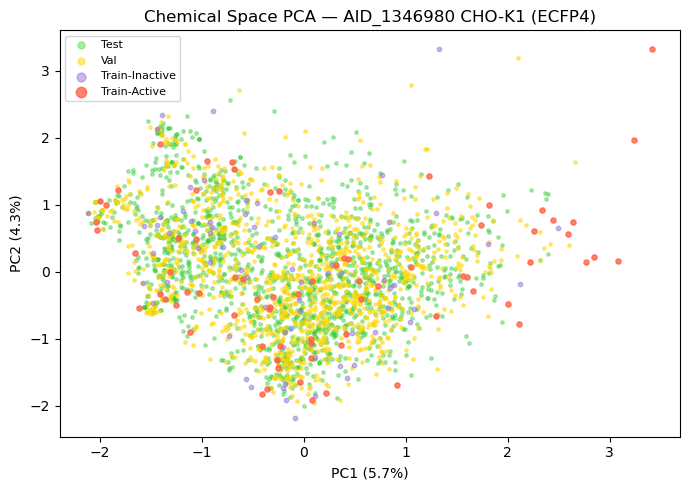

In [15]:
# ── Split Summary & Chemical Space PCA ───────────────────────────────────────
print('Split summary (% of total)')
for name, ys in [('Train',y_train),('Val',y_val),('Test',y_test)]:
    print(f'  {name:5s}: {len(ys):5,} ({100*len(ys)/len(y_all):.1f}%)  '
          f'act={( ys==1).sum()}, ina={(ys==0).sum()}')

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)
tr_p, va_p, te_p = pca.transform(X_train), pca.transform(X_val), pca.transform(X_test)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(te_p[:,0], te_p[:,1], c='limegreen', s=6, alpha=0.4, label='Test')
ax.scatter(va_p[:,0], va_p[:,1], c='gold',      s=6, alpha=0.5, label='Val')
ax.scatter(tr_p[y_train==0,0], tr_p[y_train==0,1], c='mediumpurple', s=10, alpha=0.5, label='Train-Inactive')
ax.scatter(tr_p[y_train==1,0], tr_p[y_train==1,1], c='tomato',       s=14, alpha=0.8, label='Train-Active')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Chemical Space PCA — AID_1346980 CHO-K1 (ECFP4)')
ax.legend(markerscale=2, fontsize=8); plt.tight_layout()
plt.savefig('cho_chem_space.png',dpi=150); plt.show()

Left-out inactives : 4,610
PC1: 5.7%  PC2: 4.3%  PC3: 3.0%
Total variance explained: 13.0%


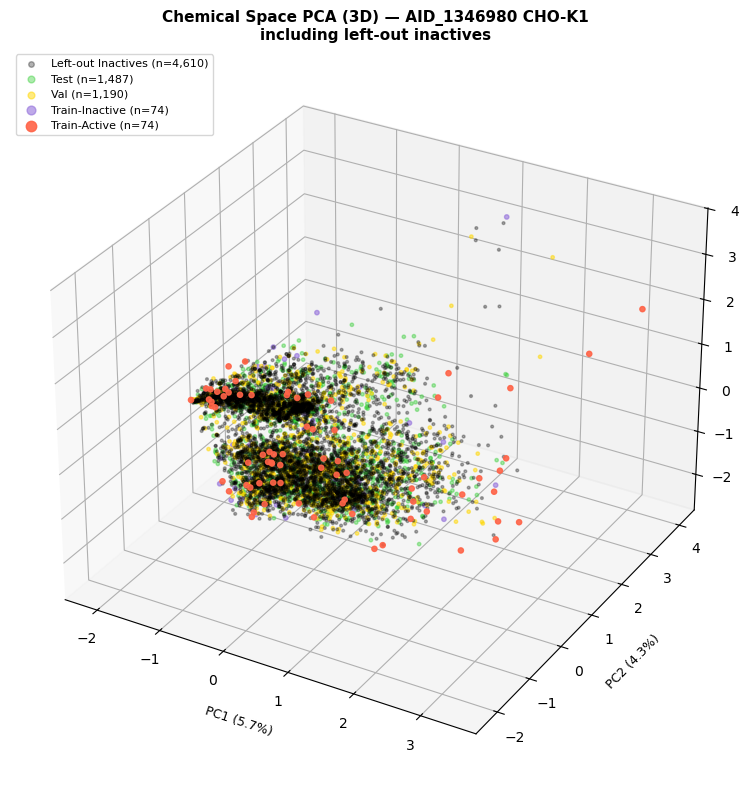

In [16]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# ── Find the left-out (discarded) inactives ──────────────────────────────────
sampled_set     = set(sampled_ina.tolist())
leftout_idx_tr  = np.array([idx for idx in ina_idx_tr
                             if idx not in sampled_set])
X_leftout       = X_tr_raw[leftout_idx_tr]

print(f'Left-out inactives : {len(leftout_idx_tr):,}')

# ── 3-component PCA ──────────────────────────────────────────────────────────
pca3 = PCA(n_components=3, random_state=SEED)
pca3.fit(X_train)

tr_3  = pca3.transform(X_train)
va_3  = pca3.transform(X_val)
te_3  = pca3.transform(X_test)
lo_3  = pca3.transform(X_leftout) if len(X_leftout) > 0 else np.zeros((0,3))

pc1_var = pca3.explained_variance_ratio_[0]*100
pc2_var = pca3.explained_variance_ratio_[1]*100
pc3_var = pca3.explained_variance_ratio_[2]*100

print(f'PC1: {pc1_var:.1f}%  PC2: {pc2_var:.1f}%  PC3: {pc3_var:.1f}%')
print(f'Total variance explained: {pc1_var+pc2_var+pc3_var:.1f}%')

fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(111, projection='3d')

if len(lo_3) > 0:
    ax.scatter(lo_3[:,0], lo_3[:,1], lo_3[:,2],
               c='black', s=4, alpha=0.3, label=f'Left-out Inactives (n={len(lo_3):,})')

ax.scatter(te_3[:,0], te_3[:,1], te_3[:,2],
           c='limegreen', s=6, alpha=0.4, label=f'Test (n={len(te_3):,})')
ax.scatter(va_3[:,0], va_3[:,1], va_3[:,2],
           c='gold', s=6, alpha=0.5, label=f'Val (n={len(va_3):,})')
ax.scatter(tr_3[y_train==0, 0], tr_3[y_train==0, 1], tr_3[y_train==0, 2],
           c='mediumpurple', s=10, alpha=0.6, label=f'Train-Inactive (n={(y_train==0).sum():,})')
ax.scatter(tr_3[y_train==1, 0], tr_3[y_train==1, 1], tr_3[y_train==1, 2],
           c='tomato', s=14, alpha=0.9, label=f'Train-Active (n={(y_train==1).sum():,})')

ax.set_xlabel(f'PC1 ({pc1_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_ylabel(f'PC2 ({pc2_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_zlabel(f'PC3 ({pc3_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_title('Chemical Space PCA (3D) — AID_1346980 CHO-K1\nincluding left-out inactives',
             fontsize=11, fontweight='bold')
ax.legend(loc='upper left', fontsize=8, markerscale=2)
plt.tight_layout()
plt.savefig('cho_chem_space_3d.png', dpi=150)
plt.show()

In [17]:
# ── 12. Metrics Helper ────────────────────────────────────────────────────────
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100,1),
        'Specificity': round(spec*100,1),
        'CCR'        : round((sens+spec)/2*100,1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob),4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob),4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred),4),
        'Bal-Acc'    : round(balanced_accuracy_score(y_true,y_pred)*100,1),
        'F1'         : round(f1_score(y_true,y_pred),4),
        'TP':tp,'TN':tn,'FP':fp,'FN':fn
    }

METRIC_COLS = ['Model','CPT','Sensitivity','Specificity','CCR',
               'ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']
print('Helpers ready.')

Helpers ready.


In [18]:
# ── 13. Random Forest Grid Search ────────────────────────────────────────────
rf_grid = ParameterGrid({
    'n_estimators'  : [300, 500],
    'max_features'  : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
    'max_depth'     : [None, 20]
})

best_rf_auc, best_rf, best_rf_params = 0, None, {}
print(f'RF: {len(rf_grid)} configs...')
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_rf_auc:
        best_rf_auc, best_rf, best_rf_params = auc, clf, p

print(f'Best RF  val AUC={best_rf_auc:.4f}  params={best_rf_params}')

RF: 16 configs...
Best RF  val AUC=0.8649  params={'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


In [19]:
# ── 14. SVM Grid Search ───────────────────────────────────────────────────────
svm_grid = ParameterGrid({
    'C'    : [1, 10, 50],
    'gamma': ['scale', 0.01, 0.001]
})

best_svm_auc, best_svm, best_svm_params = 0, None, {}
print(f'SVM: {len(svm_grid)} configs...')
for p in svm_grid:
    clf = SVC(**p, kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_svm_auc:
        best_svm_auc, best_svm, best_svm_params = auc, clf, p

print(f'Best SVM val AUC={best_svm_auc:.4f}  params={best_svm_params}')

SVM: 9 configs...
Best SVM val AUC=0.8172  params={'C': 10, 'gamma': 'scale'}


In [20]:
# ── 15. XGBoost Grid Search ──────────────────────────────────────────────────
sw = (y_train==0).sum() / (y_train==1).sum()
xgb_grid = ParameterGrid({
    'n_estimators' : [300, 500],
    'max_depth'    : [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'subsample'    : [0.8],
    'colsample_bytree': [0.8]
})

best_xgb_auc, best_xgb, best_xgb_params = 0, None, {}
print(f'XGB: {len(xgb_grid)} configs...')
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_xgb_auc:
        best_xgb_auc, best_xgb, best_xgb_params = auc, clf, p

print(f'Best XGB val AUC={best_xgb_auc:.4f}  params={best_xgb_params}')

XGB: 12 configs...
Best XGB val AUC=0.7290  params={'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 300, 'subsample': 0.8}


In [21]:
# ── 16. Classical ML — Val & Test Evaluation ─────────────────────────────────
classical = {'Random Forest': best_rf, 'SVM': best_svm, 'XGBoost': best_xgb}
cl_probs_val  = {n: clf.predict_proba(X_val)[:,1]  for n,clf in classical.items()}
cl_probs_test = {n: clf.predict_proba(X_test)[:,1] for n,clf in classical.items()}

rows_val, rows_test = [], []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_val.append(evaluate(y_val,  cl_probs_val[name],  name, cpt))
        rows_test.append(evaluate(y_test, cl_probs_test[name], name, cpt))

df_cl_val  = pd.DataFrame(rows_val)[METRIC_COLS]
df_cl_test = pd.DataFrame(rows_test)[METRIC_COLS]

print('── Classical ML — Validation Set ──')
display(df_cl_val.set_index(['Model','CPT']))
print('\n── Classical ML — Test Set ──')
display(df_cl_test.set_index(['Model','CPT']))

── Classical ML — Validation Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         77.8         80.4  79.1   0.8649  0.1782  0.1758   
              0.8         11.1         99.7  55.4   0.8649  0.1782  0.1856   
SVM           0.5         77.8         61.9  69.8   0.8172  0.1641  0.0993   
              0.8         16.7         97.1  56.9   0.8172  0.1641  0.0968   
XGBoost       0.5         77.8         59.7  68.8   0.7290  0.0898  0.0931   
              0.8         50.0         81.6  65.8   0.7290  0.0898  0.0984   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     79.1  0.1069  
              0.8     55.4  0.1667  
SVM           0.5     69.8  0.0585  
              0.8     56.9  0.1091  
XGBoost       0.5     68.8  0.0556  
              0.8     65.8  0.0741


── Classical ML — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         56.5         81.5  69.0   0.7625  0.1258  0.1193   
              0.8          4.3         99.9  52.1   0.7625  0.1258  0.1441   
SVM           0.5         69.6         63.0  66.3   0.7837  0.1223  0.0831   
              0.8         26.1         98.1  62.1   0.7837  0.1223  0.1996   
XGBoost       0.5         65.2         62.5  63.9   0.6670  0.0783  0.0705   
              0.8         52.2         83.1  67.7   0.6670  0.0783  0.1149   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     69.0  0.0847  
              0.8     52.1  0.0800  
SVM           0.5     66.3  0.0552  
              0.8     62.1  0.2105  
XGBoost       0.5     63.9  0.0511  
              0.8     67.7  0.0851

In [22]:
# ── 17. GNN Architecture ─────────────────────────────────────────────────────
class MolGNN(nn.Module):
    """
    GNN for molecular binary classification.
    GCN, GAT, GIN, GraphSAGE via conv_type argument.
    3 conv layers with BatchNorm + Residual connections.
    """

    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4):
        super().__init__()
        self.conv_type = conv_type
        self.n_layers  = n_layers
        self.drop      = nn.Dropout(dropout)

        self.proj = nn.Linear(in_dim, hidden)
        self.bn0  = nn.BatchNorm1d(hidden)

        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                self.convs.append(GATConv(hidden, hidden, heads=heads,
                                          concat=False, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(
                    nn.Linear(hidden, hidden*2),
                    nn.BatchNorm1d(hidden*2),
                    nn.ReLU(),
                    nn.Linear(hidden*2, hidden))
                self.convs.append(GINConv(mlp, train_eps=True))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))

        self.head = nn.Sequential(
            nn.Linear(hidden, hidden//2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden//2, 1)
        )

    def forward(self, x, edge_index, batch):
        x = F.relu(self.bn0(self.proj(x)))
        x = self.drop(x)
        for conv, bn in zip(self.convs, self.bns):
            x_res = x
            x = conv(x, edge_index)
            x = bn(x)
            x = F.relu(x)
            x = self.drop(x)
            x = x + x_res
        x = global_mean_pool(x, batch)
        return self.head(x).squeeze(-1)

print(f'MolGNN defined. ATOM_DIM={ATOM_DIM}')

MolGNN defined. ATOM_DIM=27


In [23]:
# ── 18. Training & Evaluation Functions ──────────────────────────────────────
def gnn_train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        loss   = criterion(logits, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)

@torch.no_grad()
def gnn_eval(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        batch = batch.to(device)
        all_logits.append(model(batch.x, batch.edge_index, batch.batch).cpu())
        all_labels.append(batch.y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    probs  = torch.sigmoid(torch.tensor(logits)).numpy()
    auc    = roc_auc_score(labels, probs)
    return probs, labels, auc

print('Training helpers defined.')

Training helpers defined.


In [24]:
# ── 19. GNN DataLoaders ──────────────────────────────────────────────────────
BATCH = 64
train_loader = DataLoader(graphs_train, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(graphs_val,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(graphs_test,  batch_size=BATCH, shuffle=False)

pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()], device=DEVICE)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f'Train graphs: {len(graphs_train)}')
print(f'Val   graphs: {len(graphs_val)}')
print(f'Test  graphs: {len(graphs_test)}')
print(f'pos_weight   : {pos_weight.item():.3f} (1.0 = balanced)')

Train graphs: 148
Val   graphs: 1190
Test  graphs: 1487
pos_weight   : 1.000 (1.0 = balanced)


In [25]:
# ── 20. Hyperparameter Grid & Training Loop ──────────────────────────────────
GNN_CONFIGS = {
    'GCN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'GAT' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
        {'hidden':128, 'n_layers':3, 'dropout':0.4, 'lr':0.0005, 'heads':8},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
    ],
    'GIN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'SAGE': [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
}

MAX_EPOCHS = 100
PATIENCE   = 20

gnn_best_models  = {}
gnn_best_configs = {}
gnn_best_val_auc = {}
gnn_history      = {}

for arch, configs in GNN_CONFIGS.items():
    print(f'\n{"="*55}')
    print(f'Architecture: {arch}  ({len(configs)} configs)')
    best_auc, best_state, best_cfg = 0, None, {}

    for cfg in configs:
        heads = cfg.pop('heads', 4)
        model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                       dropout=cfg['dropout'], conv_type=arch, heads=heads).to(DEVICE)
        opt   = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-5)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    opt, mode='max', factor=0.5, patience=10)
        cfg['heads'] = heads

        best_ep_auc, no_improv = 0, 0
        best_ep_state = None
        train_aucs, val_aucs = [], []

        for epoch in range(1, MAX_EPOCHS+1):
            loss = gnn_train_epoch(model, train_loader, opt, criterion, DEVICE)
            _,_, tr_auc = gnn_eval(model, train_loader, DEVICE)
            _,_, va_auc = gnn_eval(model, val_loader,   DEVICE)
            sched.step(va_auc)
            train_aucs.append(tr_auc); val_aucs.append(va_auc)
            if va_auc > best_ep_auc:
                best_ep_auc   = va_auc
                best_ep_state = copy.deepcopy(model.state_dict())
                no_improv = 0
            else:
                no_improv += 1
            if no_improv >= PATIENCE:
                break

        if best_ep_auc > best_auc:
            best_auc   = best_ep_auc
            best_state = best_ep_state
            best_cfg   = cfg.copy()
            gnn_history[arch] = (train_aucs, val_aucs)

        cfg_str = {k:v for k,v in cfg.items()}
        print(f'  {cfg_str}  →  val AUC={best_ep_auc:.4f}  stopped@ep{len(train_aucs)}')

    gnn_best_val_auc[arch]  = best_auc
    gnn_best_configs[arch]  = best_cfg
    gnn_best_models[arch]   = best_state
    print(f'>> Best {arch}: AUC={best_auc:.4f}  cfg={best_cfg}')


Architecture: GCN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.6768  stopped@ep32
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.7720  stopped@ep61
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  →  val AUC=0.6137  stopped@ep48
>> Best GCN: AUC=0.7720  cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}

Architecture: GAT  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.6771  stopped@ep45
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  →  val AUC=0.6486  stopped@ep54
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.7106  stopped@ep58
>> Best GAT: AUC=0.7106  cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}

Architecture: GIN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.0

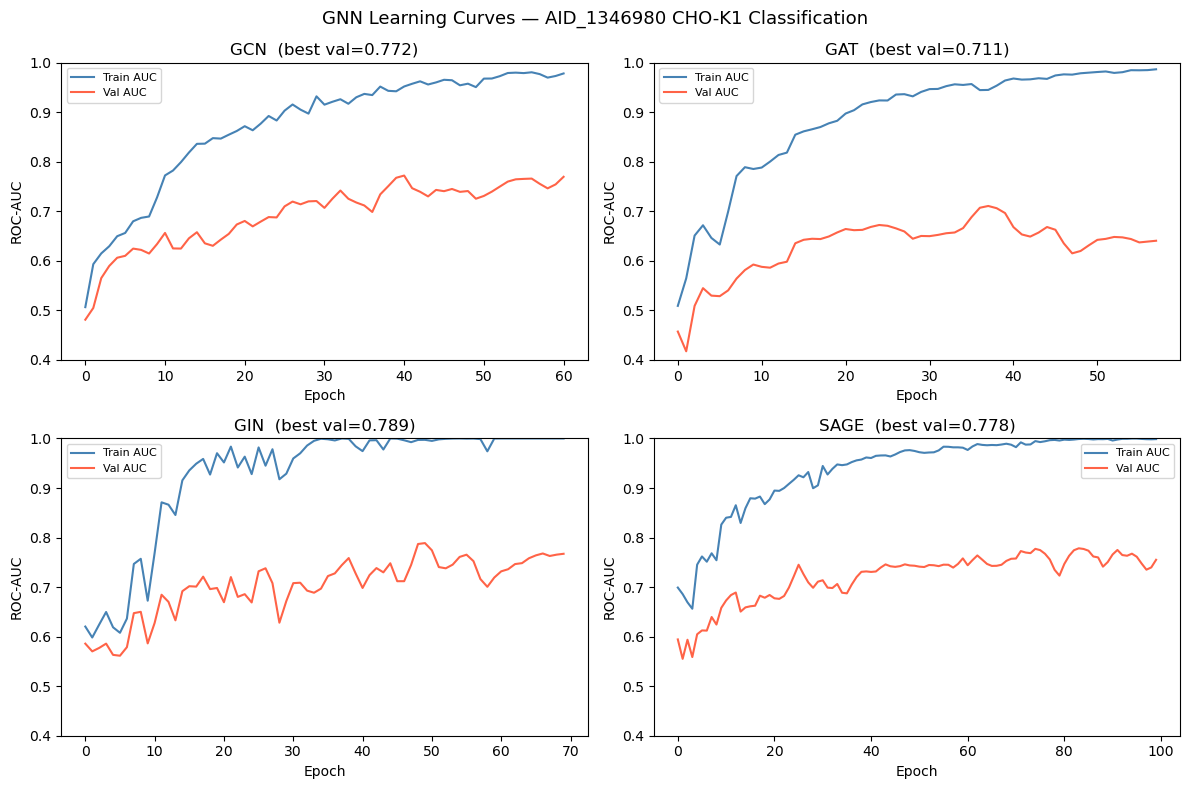

In [26]:
# ── 21. Learning Curves ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.ravel(), ['GCN','GAT','GIN','SAGE']):
    if arch in gnn_history:
        tr, va = gnn_history[arch]
        ax.plot(tr, label='Train AUC', color='steelblue')
        ax.plot(va, label='Val AUC',   color='tomato')
        ax.set_title(f'{arch}  (best val={gnn_best_val_auc[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('ROC-AUC')
        ax.legend(fontsize=8); ax.set_ylim(0.4, 1.0)
plt.suptitle('GNN Learning Curves — AID_1346980 CHO-K1 Classification', fontsize=13)
plt.tight_layout(); plt.savefig('cho_gnn_learning_curves.png',dpi=150); plt.show()

In [27]:
# ── 22. GNN Test Evaluation ──────────────────────────────────────────────────
gnn_probs_test = {}

for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads',4)).to(DEVICE)
    model.load_state_dict(state)
    probs, _, _ = gnn_eval(model, test_loader, DEVICE)
    gnn_probs_test[arch] = probs

rows_gnn = []
for arch, prob in gnn_probs_test.items():
    for cpt in [0.5, 0.8]:
        rows_gnn.append(evaluate(y_test, prob, arch, cpt))

df_gnn_test = pd.DataFrame(rows_gnn)[METRIC_COLS]
print('── GNN — Test Set ──')
display(df_gnn_test.set_index(['Model','CPT']))

── GNN — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         69.6         64.6  67.1   0.7212  0.0303  0.0879     67.1   
      0.8         21.7         86.1  53.9   0.7212  0.0303  0.0277     53.9   
GAT   0.5         47.8         70.2  59.0   0.7179  0.0397  0.0483     59.0   
      0.8         26.1         90.2  58.2   0.7179  0.0397  0.0671     58.2   
GIN   0.5         60.9         66.5  63.7   0.7427  0.0406  0.0714     63.7   
      0.8         39.1         78.6  58.8   0.7427  0.0406  0.0529     58.8   
SAGE  0.5         60.9         71.7  66.3   0.7105  0.0391  0.0886     66.3   
      0.8         34.8         85.3  60.0   0.7105  0.0391  0.0695     60.0   

               F1  
Model CPT          
GCN   0.5  0.0575  
      0.8  0.0431  
GAT   0.5  0.0467  
      0.8  0.0698  
GIN   0.5  0.0531  
      0.8  0.0520  
SAGE  0.5  0.0619  
      0.8  0.0650

In [28]:
# ── 23. Consensus: Average All Model Probabilities ───────────────────────────
all_test_probs = {**cl_probs_test, **gnn_probs_test}

consensus_prob = np.mean(list(all_test_probs.values()), axis=0)
all_test_probs['Consensus'] = consensus_prob

cl_consensus  = np.mean(list(cl_probs_test.values()), axis=0)
all_test_probs['Consensus-Classical'] = cl_consensus

gnn_consensus = np.mean(list(gnn_probs_test.values()), axis=0)
all_test_probs['Consensus-GNN'] = gnn_consensus

final_rows = []
for name, prob in all_test_probs.items():
    for cpt in [0.5, 0.8]:
        final_rows.append(evaluate(y_test, prob, name, cpt))

df_final = pd.DataFrame(final_rows)[METRIC_COLS]
print('── FULL TEST SET COMPARISON ──')
display(df_final.set_index(['Model','CPT']))

── FULL TEST SET COMPARISON ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC  \
Model               CPT                                                    
Random Forest       0.5         56.5         81.5  69.0   0.7625  0.1258   
                    0.8          4.3         99.9  52.1   0.7625  0.1258   
SVM                 0.5         69.6         63.0  66.3   0.7837  0.1223   
                    0.8         26.1         98.1  62.1   0.7837  0.1223   
XGBoost             0.5         65.2         62.5  63.9   0.6670  0.0783   
                    0.8         52.2         83.1  67.7   0.6670  0.0783   
GCN                 0.5         69.6         64.6  67.1   0.7212  0.0303   
                    0.8         21.7         86.1  53.9   0.7212  0.0303   
GAT                 0.5         47.8         70.2  59.0   0.7179  0.0397   
                    0.8         26.1         90.2  58.2   0.7179  0.0397   
GIN                 0.5         60.9         66.5  63.7   0.7427  0.0406   
                    0.8         39.1         78.6  58.8   0.7427  0.0406   
SAGE                0.5         60.9         71.7  66.3   0.7105  0.0391   
                    0.8         34.8         85.3  60.0   0.7105  0.0391   
Consensus           0.5         65.2         70.6  67.9   0.7615  0.1369   
                    0.8         17.4         97.5  57.4   0.7615  0.1369   
Consensus-Classical 0.5         65.2         68.4  66.8   0.7379  0.1430   
                    0.8         21.7         98.5  60.1   0.7379  0.1430   
Consensus-GNN       0.5         56.5         69.9  63.2   0.7336  0.0380   
                    0.8         30.4         89.5  60.0   0.7336  0.0380   

                            MCC  Bal-Acc      F1  
Model               CPT                           
Random Forest       0.5  0.1193     69.0  0.0847  
                    0.8  0.1441     52.1  0.0800  
SVM                 0.5  0.0831     66.3  0.0552  
                    0.8  0.1996     62.1  0.2105  
XGBoost             0.5  0.0705     63.9  0.0511  
                    0.8  0.1149     67.7  0.0851  
GCN                 0.5  0.0879     67.1  0.0575  
                    0.8  0.0277     53.9  0.0431  
GAT                 0.5  0.0483     59.0  0.0467  
                    0.8  0.0671     58.2  0.0698  
GIN                 0.5  0.0714     63.7  0.0531  
                    0.8  0.0529     58.8  0.0520  
SAGE                0.5  0.0886     66.3  0.0619  
                    0.8  0.0695     60.0  0.0650  
Consensus           0.5  0.0963     67.9  0.0640  
                    0.8  0.1120     57.4  0.1250  
Consensus-Classical 0.5  0.0888     66.8  0.0599  
                    0.8  0.1870     60.1  0.2000  
Consensus-GNN       0.5  0.0707     63.2  0.0545  
                    0.8  0.0796     60.0  0.0765

AD threshold  : 0.7084
Test in AD    : 237/1487 (15.9%)
  AD-filtered Sensitivity: 100.0
  AD-filtered Specificity: 78.7
  AD-filtered CCR: 89.3
  AD-filtered ROC-AUC: 0.9335
  AD-filtered MCC: 0.3136


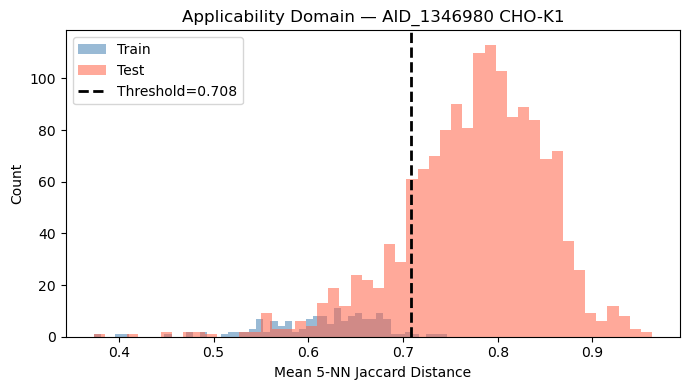

In [29]:
# ── 24. AD — k-NN Jaccard ─��──────────────────────────────────────────────────
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(X_train)
d_tr, _ = nn_ad.kneighbors(X_train)
md_tr   = d_tr.mean(axis=1)
ad_thr  = md_tr.mean() + 1.5*md_tr.std()

d_te, _ = nn_ad.kneighbors(X_test)
md_te   = d_te.mean(axis=1)
in_ad   = md_te <= ad_thr
cov     = in_ad.mean()*100

print(f'AD threshold  : {ad_thr:.4f}')
print(f'Test in AD    : {in_ad.sum()}/{len(y_test)} ({cov:.1f}%)')

if in_ad.sum() >= 20:
    m = evaluate(y_test[in_ad], consensus_prob[in_ad], 'Consensus AD', cpt=0.5)
    for k in ['Sensitivity','Specificity','CCR','ROC-AUC','MCC']:
        print(f'  AD-filtered {k}: {m[k]}')

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(md_tr, bins=50, alpha=0.55, color='steelblue', label='Train')
ax.hist(md_te, bins=50, alpha=0.55, color='tomato',    label='Test')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2,
           label=f'Threshold={ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance'); ax.set_ylabel('Count')
ax.set_title('Applicability Domain — AID_1346980 CHO-K1'); ax.legend()
plt.tight_layout(); plt.savefig('cho_ad_dist.png',dpi=150); plt.show()

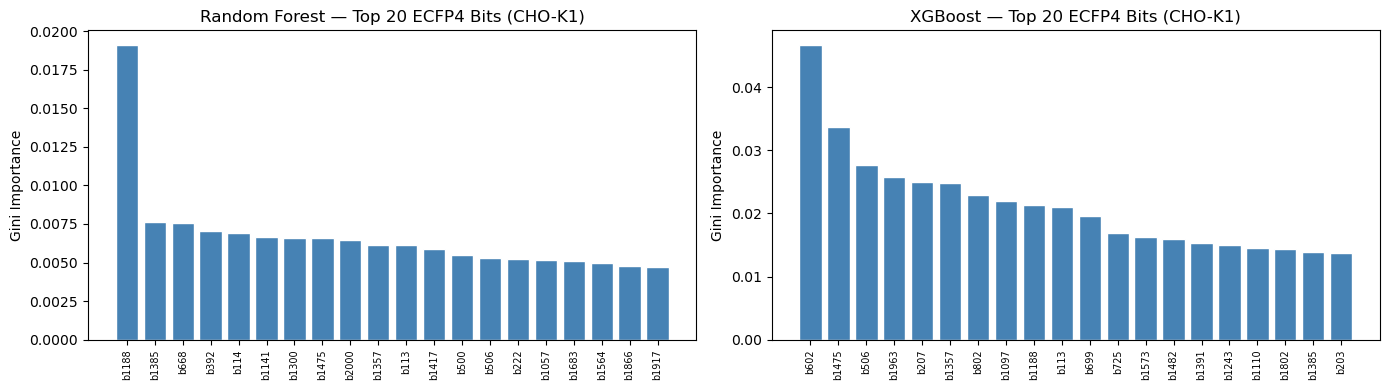

In [30]:
# ── 25. Feature Importance — RF & XGBoost ────────────────────────────────────
fig, axes = plt.subplots(1,2,figsize=(14,4))
for ax,(name,clf) in zip(axes,[('Random Forest',best_rf),('XGBoost',best_xgb)]):
    imp = clf.feature_importances_
    top = np.argsort(imp)[::-1][:20]
    ax.bar(range(20), imp[top], color='steelblue', edgecolor='white')
    ax.set_xticks(range(20))
    ax.set_xticklabels([f'b{i}' for i in top], rotation=90, fontsize=7)
    ax.set_title(f'{name} — Top 20 ECFP4 Bits (CHO-K1)'); ax.set_ylabel('Gini Importance')
plt.tight_layout(); plt.savefig('cho_feat_importance.png',dpi=150); plt.show()

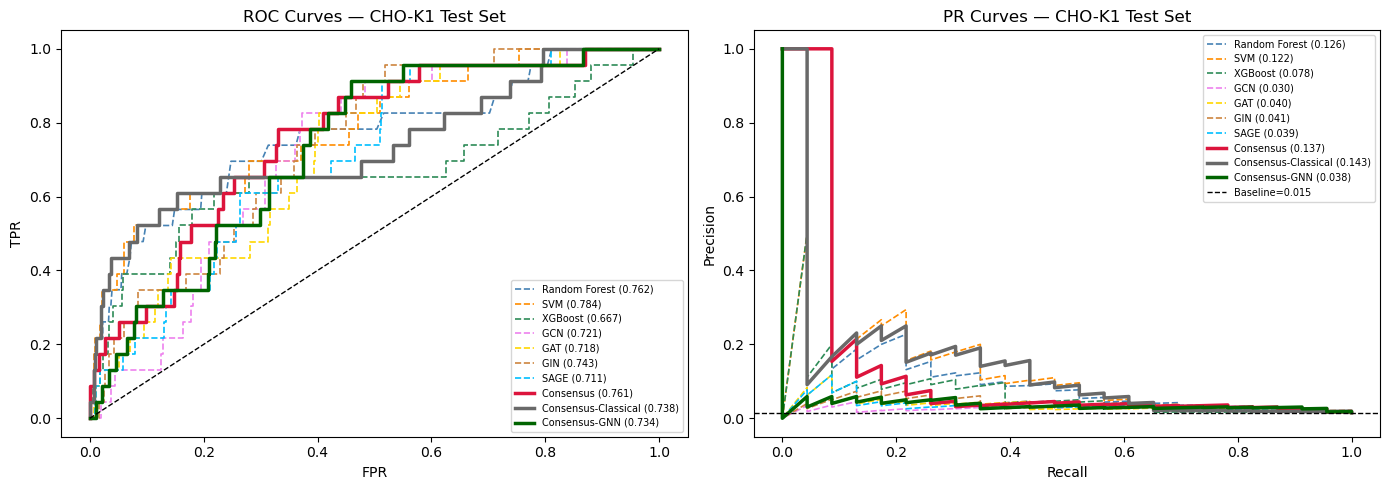

In [31]:
# ── 26. ROC & PR Curves — All Models ─────────────────────────────────────────
COLORS = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
          'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
          'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1,2,figsize=(14,5))
for name, prob in all_test_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS.get(name,'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr,tpr,_ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr,tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre,rec,_ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    axes[1].plot(rec,pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — CHO-K1 Test Set'); axes[0].legend(fontsize=7,loc='lower right')

axes[1].axhline(y_test.mean(),color='k',ls='--',lw=1,label=f'Baseline={y_test.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — CHO-K1 Test Set'); axes[1].legend(fontsize=7,loc='upper right')

plt.tight_layout(); plt.savefig('cho_roc_pr_all.png',dpi=150); plt.show()

In [32]:
# ── 27. Ranked Summary Table ──────────────────────────────────────────────────
summary_cpt1 = df_final[df_final['CPT']==0.5].drop(columns='CPT').set_index('Model')
summary_sorted = summary_cpt1.sort_values('ROC-AUC', ascending=False)
print('═'*90)
print('FINAL RANKING — AID_1346980 CHO-K1 Cytotoxicity (CPT-1, threshold≥0.50)')
print('80/20/20 split | Downsampling | Morgan ECFP4 + GNN atom/bond features')
print('═'*90)
display(summary_sorted)

print(f'\nApplicability Domain coverage: {cov:.1f}%')
summary_sorted.to_csv('cho_k1_final_results.csv')
print('Saved → cho_k1_final_results.csv')

══════════════════════════════════════════════════════════════════════════════════════════
FINAL RANKING — AID_1346980 CHO-K1 Cytotoxicity (CPT-1, threshold≥0.50)
80/20/20 split | Downsampling | Morgan ECFP4 + GNN atom/bond features
══════════════════════════════════════════════════════════════════════════════════════════


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
SVM,69.6,63.0,66.3,0.7837,0.1223,0.0831,66.3,0.0552
Random Forest,56.5,81.5,69.0,0.7625,0.1258,0.1193,69.0,0.0847
Consensus,65.2,70.6,67.9,0.7615,0.1369,0.0963,67.9,0.0640
GIN,60.9,66.5,63.7,0.7427,0.0406,0.0714,63.7,0.0531
Consensus-Classical,65.2,68.4,66.8,0.7379,0.1430,0.0888,66.8,0.0599
Consensus-GNN,56.5,69.9,63.2,0.7336,0.0380,0.0707,63.2,0.0545
GCN,69.6,64.6,67.1,0.7212,0.0303,0.0879,67.1,0.0575
GAT,47.8,70.2,59.0,0.7179,0.0397,0.0483,59.0,0.0467
SAGE,60.9,71.7,66.3,0.7105,0.0391,0.0886,66.3,0.0619



Applicability Domain coverage: 15.9%
Saved → cho_k1_final_results.csv


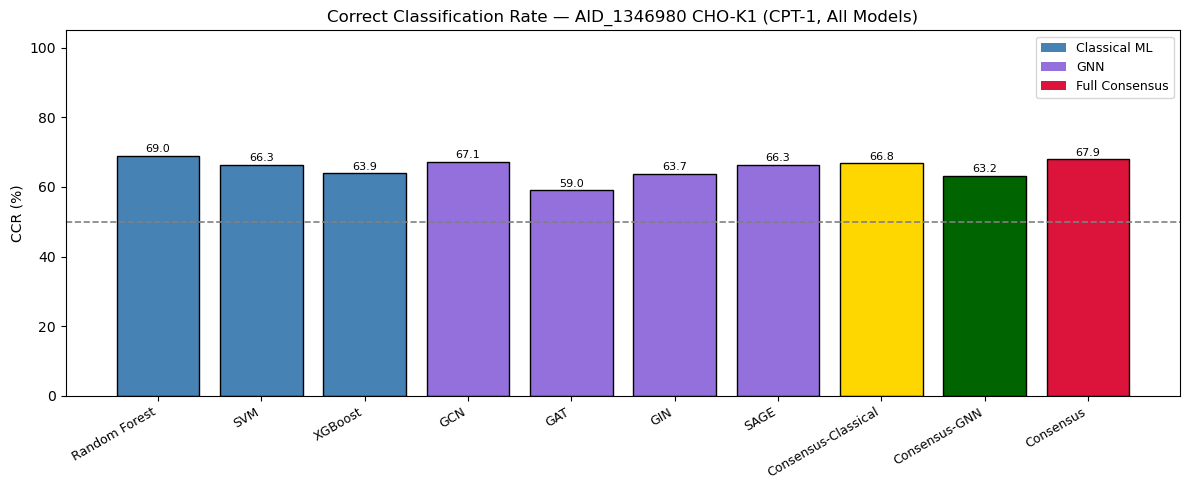

In [33]:
# ── 28. CCR Comparison Bar Chart ─────────────────────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals = [summary_cpt1.loc[m,'CCR'] if m in summary_cpt1.index else 0 for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12,5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0,105)
ax.set_title('Correct Classification Rate — AID_1346980 CHO-K1 (CPT-1, All Models)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus')]
ax.legend(handles=legend_elements, fontsize=9)
plt.tight_layout(); plt.savefig('cho_ccr_all_models.png',dpi=150); plt.show()

Best model (ROC-AUC): SVM
              precision    recall  f1-score   support

 Inactive(0)       0.99      0.63      0.77      1464
   Active(1)       0.03      0.70      0.06        23

    accuracy                           0.63      1487
   macro avg       0.51      0.66      0.41      1487
weighted avg       0.98      0.63      0.76      1487



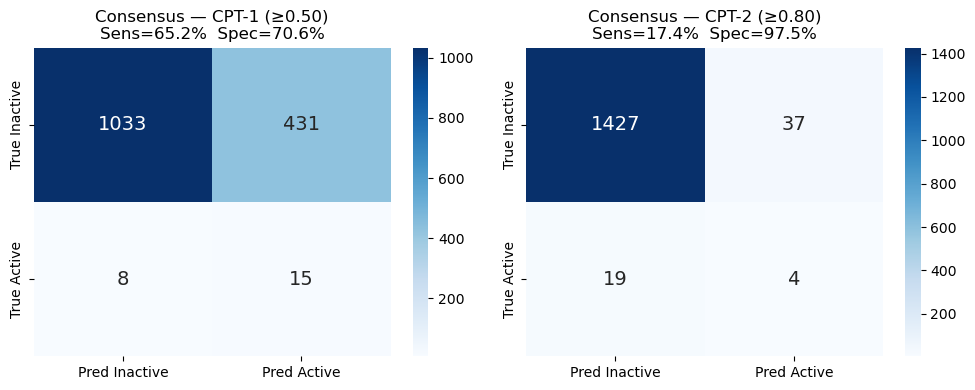

In [34]:
# ── 29. Best Model Report & Confusion Matrices ────────────────────────────────
best_name = summary_sorted.index[0]
best_prob = all_test_probs[best_name]
best_pred = (best_prob >= 0.5).astype(int)
print(f'Best model (ROC-AUC): {best_name}')
print(classification_report(y_test, best_pred, target_names=['Inactive(0)','Active(1)']))

fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, cpt, label in zip(axes,[0.5,0.8],['CPT-1 (≥0.50)','CPT-2 (≥0.80)']):
    pred = (consensus_prob >= cpt).astype(int)
    cm   = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred Inactive','Pred Active'],
                yticklabels=['True Inactive','True Active'], annot_kws={'size':14})
    tn,fp,fn,tp = cm.ravel()
    sens = tp/(tp+fn); spec = tn/(tn+fp)
    ax.set_title(f'Consensus — {label}\nSens={sens*100:.1f}%  Spec={spec*100:.1f}%')
plt.tight_layout(); plt.savefig('cho_confusion_final.png',dpi=150); plt.show()

Compound : C1=CC=C(C=C1)C(=O)C2=CC=CC=C2O
Canonical: O=C(c1ccccc1)c1ccccc1O
Mol. Weight: 198.22 Da  |  Atoms: 15

 INDIVIDUAL MODEL PROBABILITIES (P(Active) — CHO-K1 Cytotoxicity)
  Model                   P(Active)    CPT-1    CPT-2
  -------------------------------------------------------
  Random Forest              0.3433  inactive  inactive  
  SVM                        0.2316  inactive  inactive  
  XGBoost                    0.7121   ACTIVE  inactive  
  GCN                        0.3298  inactive  inactive  
  GAT                        0.4107  inactive  inactive  
  GIN                        0.4669  inactive  inactive  
  SAGE                       0.2101  inactive  inactive  
  Consensus-Classical        0.4290  inactive  inactive  
  Consensus-GNN              0.3544  inactive  inactive  
  CONSENSUS (all 7)          0.3864  inactive  inactive  ◄◄

  CONSENSUS PROBABILITY : 0.3864
  CPT-1 (≥0.50) verdict: ✓  INACTIVE (Non-Cytotoxic)
  CPT-2 (≥0.80) verdict: ✓  INACTIVE / u

[08:05:41] DEPRECATION WARNING: please use MorganGenerator


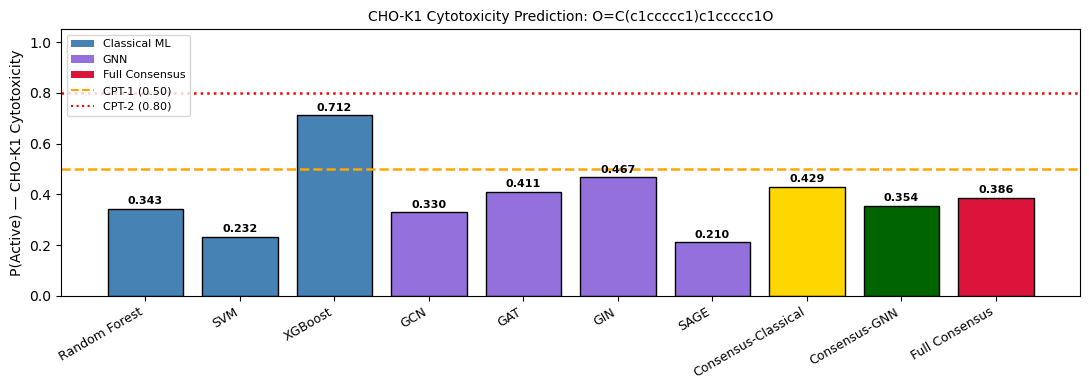

In [35]:
# ── 30. Single Compound Prediction ───────────────────────────────────────────
# ► Change TEST_SMILES to any molecule you want to predict.
# ► Set TRUE_LABEL = 1 (Active) or 0 (Inactive) if known, else None.

from rdkit.Chem import Descriptors

TEST_SMILES  = "C1=CC=C(C=C1)C(=O)C2=CC=CC=C2O"
TRUE_LABEL   = None

# ── Step A: Parse & canonicalise ─────────────────────────────────────────────
mol = Chem.MolFromSmiles(TEST_SMILES)
if mol is None:
    raise ValueError(f"RDKit could not parse SMILES: {TEST_SMILES!r}")

canon = Chem.MolToSmiles(mol)
mw    = Descriptors.MolWt(mol)
print(f"Compound : {TEST_SMILES}")
print(f"Canonical: {canon}")
print(f"Mol. Weight: {mw:.2f} Da  |  Atoms: {mol.GetNumAtoms()}")

# ── Step B: Morgan fingerprint ────────────────────────────────────────────────
fp_arr  = smiles_to_ecfp4(canon)
X_query = fp_arr.reshape(1, -1)

# ── Step C: Build graph ────────────────────────────────────────────────────────
graph_query  = mol_to_graph(canon, label=0)
query_loader = DataLoader([graph_query], batch_size=1, shuffle=False)

# ── Step D: Classical ML probabilities ────────────────────────────────────────
cl_query_probs = {}
for name, clf in classical.items():
    cl_query_probs[name] = float(clf.predict_proba(X_query)[0, 1])

# ── Step E: GNN probabilities ─────────────────────────────────────────────────
gnn_query_probs = {}
for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads', 4)).to(DEVICE)
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        batch = next(iter(query_loader)).to(DEVICE)
        logit = model(batch.x, batch.edge_index, batch.batch)
        gnn_query_probs[arch] = float(torch.sigmoid(logit).item())

# ── Step F: Consensus ─────────────────────────────────────────────────────────
all_query_probs = {**cl_query_probs, **gnn_query_probs}
consensus_q     = float(np.mean(list(all_query_probs.values())))
cl_consensus_q  = float(np.mean(list(cl_query_probs.values())))
gnn_consensus_q = float(np.mean(list(gnn_query_probs.values())))

# ── Step G: Applicability Domain check ───────────────────────────────────────
d_query, _ = nn_ad.kneighbors(X_query)
md_query   = float(d_query.mean())
in_domain  = md_query <= ad_thr

# ── Step H: Pretty print ─────────────────────────────────────────────────────
print("\n" + "="*60)
print(" INDIVIDUAL MODEL PROBABILITIES (P(Active) — CHO-K1 Cytotoxicity)")
print("="*60)
print(f"  {'Model':<22} {'P(Active)':>10}  {'CPT-1':>7}  {'CPT-2':>7}")
print("  " + "-"*55)
for name, p in {**all_query_probs,
                'Consensus-Classical': cl_consensus_q,
                'Consensus-GNN'      : gnn_consensus_q,
                'CONSENSUS (all 7)'  : consensus_q}.items():
    pred1 = "ACTIVE" if p >= 0.5 else "inactive"
    pred2 = "ACTIVE" if p >= 0.8 else "inactive"
    marker = "◄◄" if "CONSENSUS" in name else ""
    print(f"  {name:<22} {p:>10.4f}  {pred1:>7}  {pred2:>7}  {marker}")

print("="*60)
print(f"\n  CONSENSUS PROBABILITY : {consensus_q:.4f}")

cpt1_call = "⚠  ACTIVE (CHO-K1 Cytotoxic)"  if consensus_q >= 0.5 else "✓  INACTIVE (Non-Cytotoxic)"
cpt2_call = "⚠  ACTIVE (High-confidence)"    if consensus_q >= 0.8 else "✓  INACTIVE / uncertain"

print(f"  CPT-1 (≥0.50) verdict: {cpt1_call}")
print(f"  CPT-2 (≥0.80) verdict: {cpt2_call}")

ad_msg = f"INSIDE applicability domain  (dist={md_query:.4f} ≤ {ad_thr:.4f})" \
         if in_domain else \
         f"OUTSIDE applicability domain (dist={md_query:.4f} > {ad_thr:.4f}) — prediction may be unreliable"
print(f"\n  AD check   : {ad_msg}")

if TRUE_LABEL is not None:
    lbl_str = "Active (1)" if TRUE_LABEL == 1 else "Inactive (0)"
    correct = (consensus_q >= 0.5) == (TRUE_LABEL == 1)
    print(f"\n  True label : {lbl_str}  →  Prediction {'CORRECT ✓' if correct else 'WRONG ✗'}")

print("="*60)

# ── Step I: Bar chart ─────────────────────────────────────────────────────────
plot_names  = list(all_query_probs.keys()) + ['Consensus-Classical','Consensus-GNN','Full Consensus']
plot_probs  = list(all_query_probs.values()) + [cl_consensus_q, gnn_consensus_q, consensus_q]
plot_colors = (['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson'])

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(plot_names, plot_probs, color=plot_colors, edgecolor='black')
ax.axhline(0.5, color='orange', lw=1.8, ls='--', label='CPT-1 (0.50)')
ax.axhline(0.8, color='red',    lw=1.8, ls=':',  label='CPT-2 (0.80)')
for b, p in zip(bars, plot_probs):
    ax.text(b.get_x() + b.get_width()/2, p + 0.01, f'{p:.3f}',
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.set_ylabel('P(Active) — CHO-K1 Cytotoxicity')
ax.set_title(f'CHO-K1 Cytotoxicity Prediction: {canon}', fontsize=10)
ax.set_xticklabels(plot_names, rotation=30, ha='right', fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus'),
                   plt.Line2D([0],[0],color='orange',ls='--',label='CPT-1 (0.50)'),
                   plt.Line2D([0],[0],color='red',   ls=':' ,label='CPT-2 (0.80)')],
          fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig('cho_single_compound_prediction.png', dpi=150)
plt.show()

In [36]:
# ── Save base model probabilities for Consensus (Full+GT) computation ─────────
base_keys  = ['Random Forest', 'SVM', 'XGBoost', 'GCN', 'GAT', 'GIN', 'SAGE']
base_probs = {k: all_test_probs[k] for k in base_keys if k in all_test_probs}
np.save('chok1_base_probs_test.npy', base_probs)
np.save('chok1_y_test.npy',          y_test)
print(f'Saved {len(base_probs)} models: {list(base_probs.keys())}')
print(f'y_test size: {len(y_test)}  actives={y_test.sum()}')

Saved 7 models: ['Random Forest', 'SVM', 'XGBoost', 'GCN', 'GAT', 'GIN', 'SAGE']
y_test size: 1487  actives=23
